# Neighborhood poverty and nearby fossil-fuel capacity
**California · 2023 · CSS211**

Does the poverty association persist when the radius changes, when influential locations are omitted, and when urban density and manufacturing employment are considered? The primary radius is 5 km. Each tract receives equal weight in the regressions. The resident comparison uses ACS population counts.

**Run order.** Place this notebook alongside DataCleaning.ipynb and use its two files in data/processed. Run the cells in order. The first geographic analysis downloads 2023 TIGER/Line tract boundaries and County Business Patterns once. Tables and PNG figures are written to outputs/css211_ca. The saved outputs can be read without rerunning. In Miniforge, the environment needs pandas, numpy, pyarrow, scipy, statsmodels, geopandas, matplotlib, requests, scikit-learn, threadpoolctl and ipykernel.

In [1]:
%pip install geopandas

   ---------------------------------------- 0.0/23.8 MB ? eta -:--:--
   ----------- ---------------------------- 6.8/23.8 MB 34.0 MB/s eta 0:00:01
   ------------------------ --------------- 14.4/23.8 MB 35.6 MB/s eta 0:00:01
   ------------------------------------- -- 22.3/23.8 MB 36.0 MB/s eta 0:00:01
   ---------------------------------------- 23.8/23.8 MB 35.2 MB/s  0:00:00
   ---------------------------------------- 0.0/6.9 MB ? eta -:--:--
   ---------------------------------------- 6.9/6.9 MB 39.3 MB/s  0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 1.8/1.8 MB 41.5 MB/s  0:00:00

   ---------------------------------------- 0/4 [shapely]
   ---------------------------------------- 0/4 [shapely]
   ---------- ----------------------------- 1/4 [pyproj]
   -------------------- ------------------- 2/4 [pyogrio]
   -------------------- ------------------- 2/4 [pyogrio]
   ------------------------------ --------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.special import expit
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
from sklearn.neighbors import BallTree
from threadpoolctl import threadpool_limits
import requests

base = Path("data/processed")
out = Path("outputs/css211_ca")
out.mkdir(parents=True, exist_ok=True)
raw = Path("data/raw")
raw.mkdir(parents=True, exist_ok=True)
t = pd.read_parquet(base / "tract_selfgen_proximity_06_2023.parquet")
p = pd.read_parquet(base / "potential_selfgen_fossil_plants_2023.parquet")
assert t.tract_geoid.is_unique and p.plant_id_eia.is_unique
assert t.tract_geoid.str[:2].eq("06").all()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
blue, rust = "#206879", "#B45033"

def table(frame, name):
    frame.to_csv(out / f"{name}.csv", index=False)
    display(frame.round(3))

def figure(fig, name):
    fig.tight_layout()
    fig.savefig(out / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1 · Which plants are nearby?
Rebuild the tract–plant pairs once through 10 km using the original 6,371 km Earth radius. Keep plants across state borders. Verify every count and MW total against the cleaning notebook before fitting models.

68 distinct plants contribute to California's 5 km results.


plant_id_eia  plant_name_eia
50849         PE Berkeley       65
Name: one_plant_28_5_MW_tracts, dtype: int64

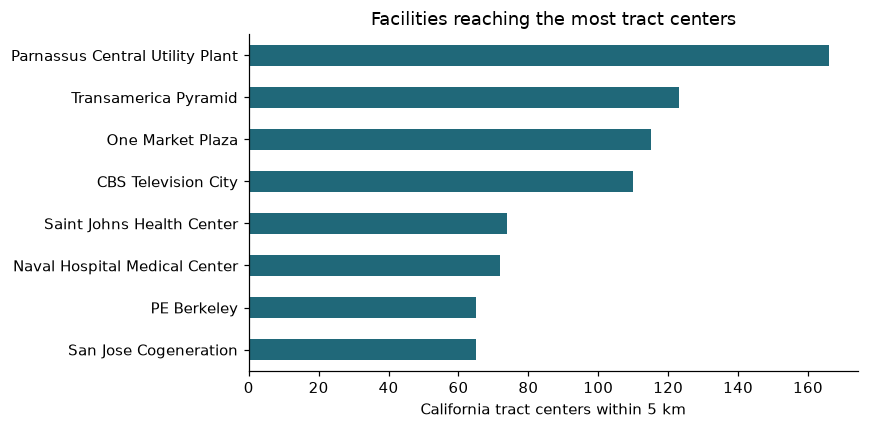

In [2]:
sites = p.loc[p.coordinates_valid.fillna(False)].reset_index(drop=True)
centers = t.dropna(subset=["tract_lat", "tract_lon"]).reset_index(drop=True)
tree = BallTree(np.radians(sites[["latitude","longitude"]].astype(float)), metric="haversine")
ids, distances = tree.query_radius(np.radians(centers[["tract_lat","tract_lon"]].astype(float)),
                                   r=10/6371, return_distance=True)
pairs = pd.DataFrame({"tract_geoid": np.repeat(centers.tract_geoid.to_numpy(), [len(x) for x in ids]),
                      "plant_row": np.concatenate(ids), "km": np.concatenate(distances)*6371})
pairs = pairs.join(sites[["plant_id_eia","plant_name_eia","fossil_capacity_mw"]], on="plant_row")
assert not pairs.duplicated(["tract_geoid","plant_id_eia"]).any()
pairs.drop(columns="plant_row").to_parquet(out / "tract_plant_pairs_10km.parquet", index=False)
for r in [2,5,10]:
    g = pairs.loc[pairs.km <= r].groupby("tract_geoid").fossil_capacity_mw
    n = centers.tract_geoid.map(g.size()).fillna(0)
    total = centers.tract_geoid.map(g.sum()).where(n > 0, 0)
    total = total.mask(centers.tract_geoid.map(g.count()).fillna(0) < n)
    np.testing.assert_allclose(n, centers[f"plant_count_{r}km"])
    np.testing.assert_allclose(total.astype(float), centers[f"capacity_mw_{r}km"].astype(float), equal_nan=True)
near = pairs.loc[pairs.km <= 5].copy()
reach = (near.groupby(["plant_id_eia","plant_name_eia","fossil_capacity_mw"],as_index=False)
         .agg(tracts=("tract_geoid","nunique")).sort_values(["tracts","plant_id_eia"],ascending=[False,True]))
reach.to_csv(out/"facility_reach.csv",index=False)
print(f"{len(reach)} distinct plants contribute to California's 5 km results.")
example = t.loc[t.plant_count_5km.eq(1) & np.isclose(t.capacity_mw_5km.astype(float),28.5),"tract_geoid"]
display(near.loc[near.tract_geoid.isin(example)].groupby(["plant_id_eia","plant_name_eia"]).size().rename("one_plant_28_5_MW_tracts"))
fig, ax = plt.subplots(figsize=(8,4))
reach.head(8).sort_values("tracts").plot.barh(x="plant_name_eia", y="tracts", legend=False, color=blue, ax=ax)
ax.set(xlabel="California tract centers within 5 km",ylabel="",title="Facilities reaching the most tract centers")
figure(fig,"facility_reach")

## 2 · Radius sensitivity for the two-part model
Presence uses variational Bayesian logistic regression with a county intercept. Amount uses maximum-likelihood linear mixed regression of log positive MW. Both adjust for centered log population and poverty per 10 percentage points. Intervals are approximate posterior credible intervals for odds ratios and Wald confidence intervals for geometric-mean differences. The logistic ICC is on the latent scale.

,km,tracts,positive,positive_counties,odds_ratio,or_low,or_high,amount_pct,pct_low,pct_high,presence_icc,amount_icc,bic_amount,bic_ols
0,2,9053,378,17,1.442,1.323,1.573,13.250,2.592,25.015,0.442,0.356,1280.625,1336.564
1,5,9053,1584,18,1.079,1.016,1.145,10.117,2.805,17.949,0.676,0.352,5484.251,5747.069
2,10,9053,3647,21,1.124,1.068,1.183,-14.009,-18.444,-9.333,0.785,0.301,13518.135,13966.489


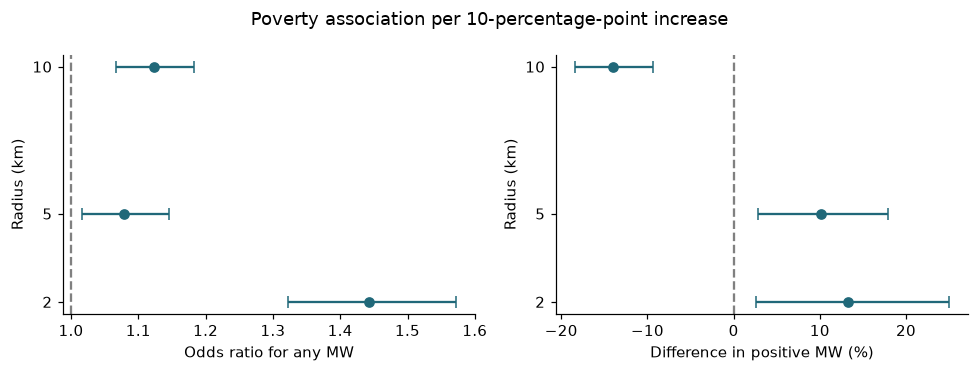

In [3]:
cols = ["poverty_pct","population","county_fips","tract_geoid","tract_lat","tract_lon"]
d = t.dropna(subset=cols).loc[lambda x:x.population.gt(0)].copy()
d["county_fips"] = d.county_fips.astype(str)
d["poverty_pct"] = d.poverty_pct.astype(float)
d["pov"] = (d.poverty_pct - d.poverty_pct.mean()) / 10
d["lp"] = np.log(d.population.astype(float))
d["lp"] -= d.lp.mean()

def amount_fit(pos, rhs):
    model = smf.mixedlm("log_mw ~ "+rhs, pos, groups=pos.county_fips)
    fit = model.fit(reml=False, method="powell", disp=False)
    if not fit.converged:
        raise RuntimeError("Positive-capacity model did not converge")
    return fit

def fit_parts(frame, radius, rhs="pov + lp"):
    col = f"capacity_mw_{radius}km"
    a = frame.dropna(subset=[col]).copy()
    a["any_mw"] = a[col].gt(0).astype(int)
    pos = a.loc[a.any_mw.eq(1)].copy()
    pos["log_mw"] = np.log(pos[col].astype(float))
    with threadpool_limits(limits=1):
        model = BinomialBayesMixedGLM.from_formula("any_mw ~ "+rhs, {"county":"0+C(county_fips)"}, a, vcp_p=0.5)
        np.random.seed(211)
        binary = model.fit_vb()
        if not binary.optim_retvals.success:
            raise RuntimeError(str(binary.optim_retvals.message))
        amount = amount_fit(pos,rhs)
    j = model.exog_names.index("pov")
    b, sd = binary.fe_mean[j], binary.fe_sd[j]
    est, low, high = 100*np.expm1([amount.fe_params["pov"], *amount.conf_int().loc["pov"]])
    v = amount.cov_re.iloc[0,0]
    vb = np.exp(2*binary.vcp_mean[0])
    row = dict(km=radius, tracts=len(a), positive=len(pos), positive_counties=pos.county_fips.nunique(),
               odds_ratio=np.exp(b), or_low=np.exp(b-1.96*sd), or_high=np.exp(b+1.96*sd),
               amount_pct=est, pct_low=low, pct_high=high, presence_icc=vb/(vb+np.pi**2/3),
               amount_icc=v/(v+amount.scale), bic_amount=amount.bic, bic_ols=smf.ols("log_mw ~ "+rhs,pos).fit().bic)
    return row, a, pos, binary, amount

fits = {r:fit_parts(d,r) for r in [2,5,10]}
rad = pd.DataFrame([fit[0] for fit in fits.values()])
table(rad,"radius_models")
_, a, pos, binary, amount = fits[5]
fig, axs = plt.subplots(1,2,figsize=(9,3.4))
for ax, val, lo, hi, ref, label in [
    (axs[0],"odds_ratio","or_low","or_high",1,"Odds ratio for any MW"),
    (axs[1],"amount_pct","pct_low","pct_high",0,"Difference in positive MW (%)")]:
    ax.errorbar(rad[val], rad.km, xerr=[rad[val]-rad[lo],rad[hi]-rad[val]],fmt="o",color=blue,capsize=4)
    ax.axvline(ref,color="grey",ls="--")
    ax.set(yticks=[2,5,10],ylabel="Radius (km)",xlabel=label)
fig.suptitle("Poverty association per 10-percentage-point increase")
figure(fig,"radius_models")

## 3 · Counts versus generating scale
Define quartiles using all eligible 5 km model tracts, then summarize the positive subset. MW per plant is calculated separately for each tract before averaging. A facility may contribute to many tracts.

,quartile,positive_tracts,mean_plants,mean_total_mw,median_total_mw,mean_mw_per_plant
0,Q1 · lowest,376,1.290,33.874,9.2,26.938
1,Q2,432,1.308,30.641,7.0,24.226
2,Q3,396,1.331,31.249,6.1,22.672
3,Q4 · highest,380,1.442,36.614,8.9,23.004


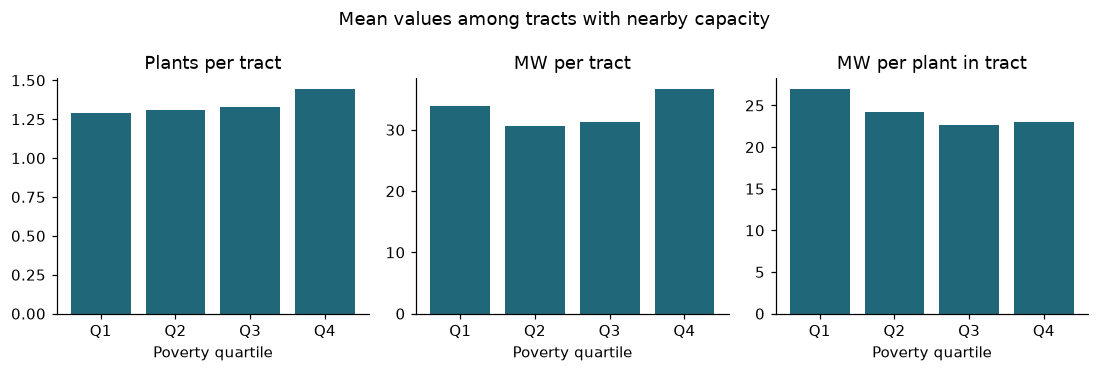

In [4]:
a = a.copy()
a["quartile"] = pd.qcut(a.poverty_pct,4,labels=["Q1 · lowest","Q2","Q3","Q4 · highest"])
q = a.loc[a.any_mw.eq(1)].copy()
q["mw_per_plant"] = q.capacity_mw_5km / q.plant_count_5km
quart = q.groupby("quartile",observed=True).agg(positive_tracts=("tract_geoid","size"),
    mean_plants=("plant_count_5km","mean"), mean_total_mw=("capacity_mw_5km","mean"),
    median_total_mw=("capacity_mw_5km","median"), mean_mw_per_plant=("mw_per_plant","mean")).reset_index()
table(quart,"quartiles")
fig, axs = plt.subplots(1,3,figsize=(10,3.4))
for ax,col,label in zip(axs,["mean_plants","mean_total_mw","mean_mw_per_plant"],["Plants per tract","MW per tract","MW per plant in tract"]):
    ax.bar(["Q1","Q2","Q3","Q4"],quart[col],color=blue)
    ax.set(title=label,xlabel="Poverty quartile")
fig.suptitle("Mean values among tracts with nearby capacity")
figure(fig,"quartiles")

## 4 · Influence of counties and facilities
Refit the positive-capacity model after omitting each represented county. Rank facilities both by number of tracts reached and by MW multiplied by that count (a measure of influence on tract totals). Remove the leader of each ranking, subtract its MW from every affected tract, then rebuild the positive sample.

,omission,label,positive,amount_pct
5,county,06037,1149,6.569
9,county,06073,1349,7.404
8,county,06071,1485,9.707
2,county,06013,1544,9.765
19,plant,Watson Cogeneration,1562,10.079
11,county,06077,1583,10.081
12,county,06081,1559,10.152
7,county,06065,1559,10.193
14,county,06087,1573,10.223
6,county,06059,1456,10.250


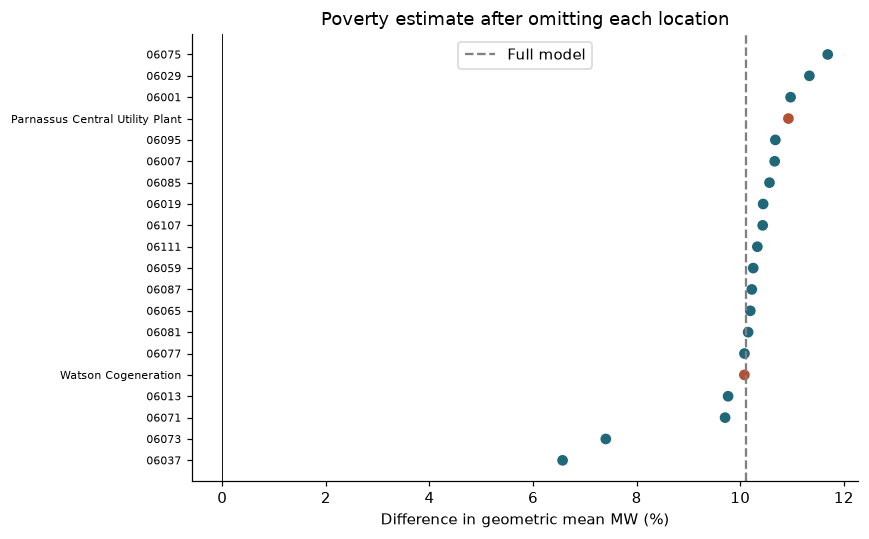

In [5]:
influence = []
def record_fit(kind, label, sample):
    with threadpool_limits(limits=1):
        fit = amount_fit(sample,"pov + lp")
    influence.append(dict(omission=kind,label=label,positive=len(sample),amount_pct=100*np.expm1(fit.fe_params["pov"])))
for county in sorted(pos.county_fips.unique()):
    record_fit("county",county,pos.loc[pos.county_fips.ne(county)])
reach["mw_times_tracts"] = reach.fossil_capacity_mw * reach.tracts
leaders = pd.concat([reach.head(1),reach.nlargest(1,"mw_times_tracts")]).drop_duplicates("plant_id_eia")
for site in leaders.itertuples():
    affected = near.loc[near.plant_id_eia.eq(site.plant_id_eia),"tract_geoid"]
    adjusted = pos.copy()
    mw = adjusted.capacity_mw_5km - adjusted.tract_geoid.isin(affected)*site.fossil_capacity_mw
    adjusted = adjusted.loc[mw.gt(1e-8)].copy()
    adjusted["log_mw"] = np.log(mw.loc[adjusted.index].astype(float))
    record_fit("plant",site.plant_name_eia,adjusted)
inf = pd.DataFrame(influence).sort_values("amount_pct")
table(inf,"influence")
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(inf.amount_pct, range(len(inf)),c=inf.omission.map({"county":blue,"plant":rust}))
ax.set_yticks(range(len(inf)),inf.label,fontsize=7)
ax.axvline(rad.loc[rad.km.eq(5),"amount_pct"].iloc[0],ls="--",color="grey",label="Full model")
ax.axvline(0,color="black",lw=.6)
ax.set(xlabel="Difference in geometric mean MW (%)",title="Poverty estimate after omitting each location")
ax.legend()
figure(fig,"influence")

## 5 · Geography and model diagnostics
Maps show tract boundaries, population centers, and 5 km circles around qualifying sites in or near San Francisco and Kern counties. The examples contrast compact urban tracts with a county containing extensive rural areas. Projection is California Albers (EPSG:3310). Diagnostics use conditional residuals from the primary positive-MW model.

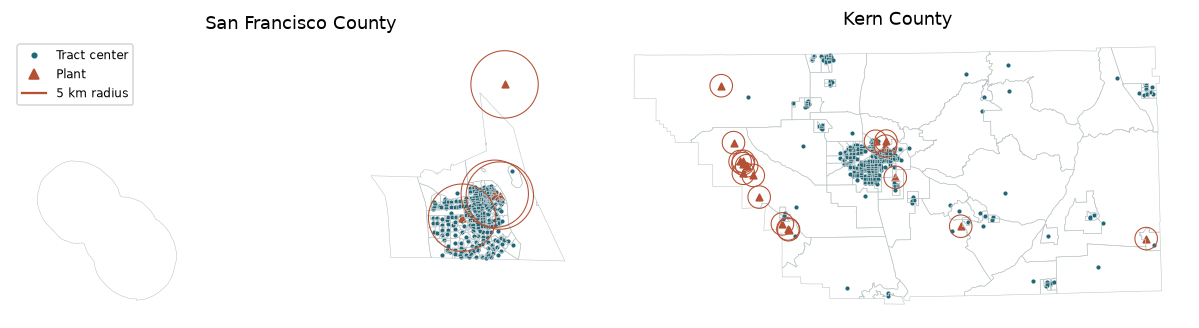

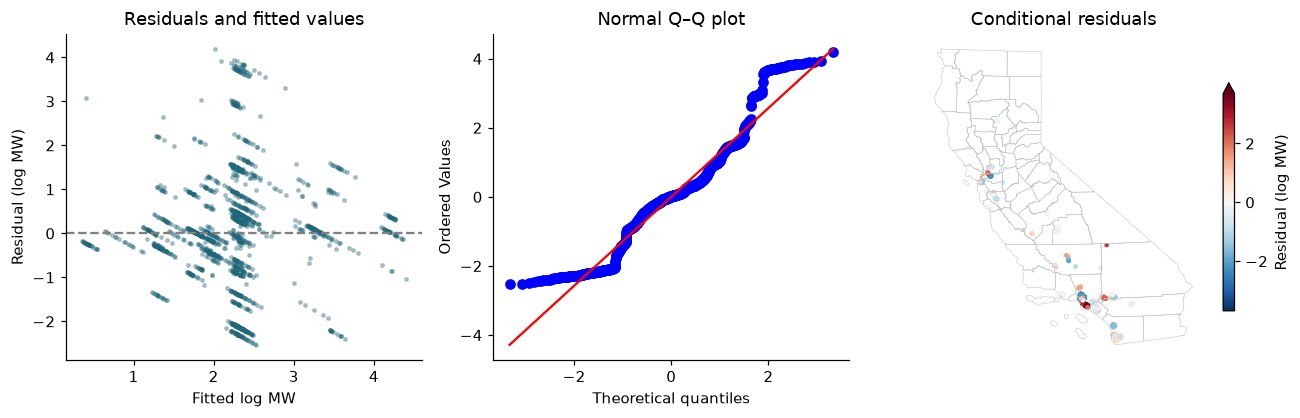

In [6]:
def download(filename,url):
    path = raw / filename
    if not path.exists():
        tmp = path.with_suffix(".part")
        with requests.get(url,stream=True,timeout=120) as res:
            res.raise_for_status()
            with tmp.open("wb") as f:
                for chunk in res.iter_content(1024*1024):
                    f.write(chunk)
        tmp.replace(path)
    return path

shp = download("tl_2023_06_tract.zip","https://www2.census.gov/geo/tiger/TIGER2023/TRACT/tl_2023_06_tract.zip")
geo = gpd.read_file(shp)[["GEOID","ALAND","geometry"]].to_crs(3310)
geo["county_fips"] = geo.GEOID.str[:5]
def points(frame,x,y):
    return gpd.GeoDataFrame(frame.copy(), geometry=gpd.points_from_xy(frame[x], frame[y]),crs=4326).to_crs(3310)
cg = points(centers,"tract_lon","tract_lat")
pg = points(sites,"longitude","latitude")
fig, axs = plt.subplots(1,2,figsize=(11,5))
for ax,county,name in zip(axs,["06075","06029"],["San Francisco","Kern"]):
    tr = geo.loc[geo.county_fips.eq(county)]
    boundary = tr.geometry.union_all()
    nearby = pg.loc[pg.distance(boundary) <= 5000]
    tr.boundary.plot(ax=ax,color="#bbc5c6",linewidth=.35)
    cg.loc[cg.county_fips.eq(county)].plot(ax=ax,color=blue,markersize=3)
    if len(nearby):
        nearby.buffer(5000).boundary.plot(ax=ax,color=rust,linewidth=.7)
        nearby.plot(ax=ax,color=rust,marker="^",markersize=19)
    ax.set_title(name+" County")
    ax.set_axis_off()
axs[0].legend(handles=[Line2D([],[],marker=".",ls="",color=blue,label="Tract center"),
    Line2D([],[],marker="^",ls="",color=rust,label="Plant"),Line2D([],[],color=rust,label="5 km radius")],fontsize=8)
figure(fig,"county_maps")

resid = amount.resid
fig, axs = plt.subplots(1,3,figsize=(12,3.9))
axs[0].scatter(amount.fittedvalues,resid,s=5,alpha=.32,color=blue)
axs[0].axhline(0,color="grey",ls="--")
axs[0].set(xlabel="Fitted log MW",ylabel="Residual (log MW)",title="Residuals and fitted values")
stats.probplot(resid,plot=axs[1])
axs[1].set_title("Normal Q–Q plot")
outline = geo.dissolve(by="county_fips").boundary
outline.plot(ax=axs[2],color="#bcc5c6",linewidth=.35)
limit = np.quantile(np.abs(resid),.98)
rp = points(pos.assign(residual=resid),"tract_lon","tract_lat")
rp.plot(ax=axs[2],column="residual",cmap="RdBu_r",vmin=-limit,vmax=limit,markersize=4,
        legend=True,legend_kwds={"label":"Residual (log MW)","shrink":.7})
axs[2].set_title("Conditional residuals")
axs[2].set_axis_off()
figure(fig,"diagnostics")

## 6 · Density and industrial context
Density uses ACS population divided by TIGER land area (km²). County manufacturing jobs use the aggregate NAICS 31–33 row from 2023 County Business Patterns. This is county workplace employment. Missing industry rows remain unknown. Compare adjusted and baseline models on identical records.

In [7]:
context = d.merge(geo[["GEOID","ALAND"]],left_on="tract_geoid",right_on="GEOID",validate="one_to_one",how="left")
context["density"] = np.log(context.population.astype(float)/(context.ALAND.where(context.ALAND.gt(0))/1e6))
cbpfile = download("cbp23co.zip","https://www2.census.gov/programs-surveys/cbp/datasets/2023/cbp23co.zip")
cbp = pd.read_csv(cbpfile,usecols=["fipstate","fipscty","naics","emp"],dtype=str)
jobs = cbp.loc[cbp.fipstate.eq("06") & cbp.naics.eq("31----")].copy()
jobs["county_fips"] = jobs.fipstate + jobs.fipscty
jobs["jobs"] = np.log1p(pd.to_numeric(jobs.emp,errors="coerce"))
context = context.merge(jobs[["county_fips","jobs"]],on="county_fips",how="left",validate="many_to_one")
ctx_rows = []
for factors in [["density"],["density","jobs"]]:
    common = context.dropna(subset=factors).copy()
    for factor in factors:
        common[factor] = (common[factor]-common[factor].mean()) / common[factor].std()
    for label,rhs in [("baseline","pov + lp"),("adjusted","pov + lp + "+" + ".join(factors))]:
        row = fit_parts(common,5,rhs)[0]
        ctx_rows.append(dict(sample=" + ".join(factors),model=label,**row))
table(pd.DataFrame(ctx_rows),"context_models")

,sample,model,km,tracts,positive,positive_counties,odds_ratio,or_low,or_high,amount_pct,pct_low,pct_high,presence_icc,amount_icc,bic_amount,bic_ols
0,density,baseline,5,9053,1584,18,1.079,1.016,1.145,10.117,2.805,17.949,0.676,0.352,5484.251,5747.069
1,density,adjusted,5,9053,1584,18,0.930,0.873,0.989,12.865,5.166,21.127,0.617,0.370,5483.732,5753.629
2,density + jobs,baseline,5,9042,1584,18,1.079,1.016,1.145,10.117,2.805,17.949,0.678,0.352,5484.251,5747.069
3,density + jobs,adjusted,5,9042,1584,18,0.933,0.877,0.993,12.954,5.248,21.225,0.619,0.364,5490.617,5760.996


## 7 · Expected MW across all eligible tracts
Set each tract's poverty to 10% and then 20%, preserving its population and county. Multiply the fitted presence probability by conditional arithmetic mean MW. The lognormal correction uses half the fitted residual variance. For counties without positive observations, integrate the amount intercept over its fitted distribution. For represented counties use the estimated county intercept. These are plug-in scenario estimates with extrapolation in all-zero counties. They assume the two models' county effects are independent when one is unobserved. A separate supported-county summary shows the effect of that choice.

In [8]:
county_v = amount.cov_re.iloc[0,0]
amount_offsets = {str(k):float(v.iloc[0]) for k,v in amount.random_effects.items()}
binary_offsets = {name.split("[")[-1].rstrip("]"):v for name,v in zip(binary.model.vc_names,binary.vc_mean)}
assert set(a.county_fips) <= set(binary_offsets)
poverty_center = d.poverty_pct.mean()
prediction_rows = []
for level in [10,20]:
    scenario = a.assign(pov=(level-poverty_center)/10)
    X = scenario.assign(Intercept=1.0)[binary.model.exog_names].to_numpy()
    prob = expit(X @ binary.fe_mean + scenario.county_fips.map(binary_offsets).to_numpy())
    offset = scenario.county_fips.map(amount_offsets)
    known = offset.notna()
    mean_pos = np.exp(amount.predict(scenario) + offset.fillna(0) + amount.scale/2 + (~known)*county_v/2)
    for target,mask in [("All eligible tracts",np.ones(len(scenario),dtype=bool)),("Positive-support counties",known)]:
        prediction_rows.append(dict(target=target,poverty_pct=level,tracts=int(mask.sum()),
                                    expected_mw=(prob*mean_pos)[mask].mean()))
pred = pd.DataFrame(prediction_rows)
table(pred,"expected_mw")
display(pred.pivot(index="target",columns="poverty_pct",values="expected_mw").diff(axis=1)[20].rename("difference_MW_20_minus_10"))

,target,poverty_pct,tracts,expected_mw
0,All eligible tracts,10,9053,4.855
1,Positive-support counties,10,7375,5.949
2,All eligible tracts,20,9053,5.641
3,Positive-support counties,20,7375,6.912


target
All eligible tracts          0.785794
Positive-support counties    0.962570
Name: difference_MW_20_minus_10, dtype: float64

## 8 · Resident proximity and public health interpretation
The percentages below use ACS counts of residents with known poverty status and known tract proximity. A person is assigned their tract center's proximity once. The unit of the regression is a tract. Installed MW describes infrastructure scale. Operating hours, emissions, dispersion and health outcomes would be needed for an exposure or health-effects study.

,group,residents,nearby,percent
0,Below poverty,4610600,772709,16.759
1,At or above poverty,33918852,5603116,16.519


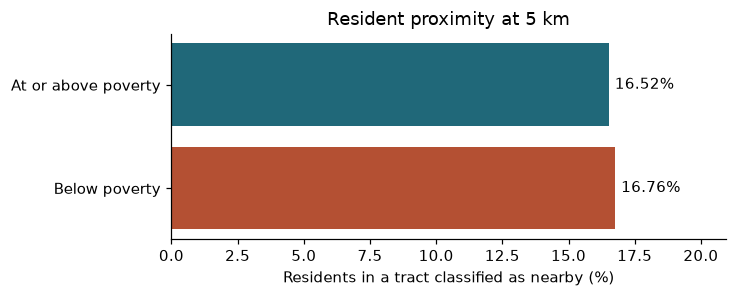

Resident proximity gap (below minus at/above poverty): +0.24 percentage points.
2 km: adjusted presence OR 1.44; positive MW difference +13.2% (95% CI +2.6 to +25.0%).
5 km: adjusted presence OR 1.08; positive MW difference +10.1% (95% CI +2.8 to +17.9%).
10 km: adjusted presence OR 1.12; positive MW difference -14.0% (95% CI -18.4 to -9.3%).
These observational comparisons use sector-screened potential self-generators. Neighboring tracts can share plants; county grouping may leave local spatial dependence.


In [9]:
people = t.dropna(subset=["plant_count_5km","below_poverty","at_or_above_poverty"])
is_near = people.plant_count_5km.gt(0)
resident = []
for label,col in [("Below poverty","below_poverty"),("At or above poverty","at_or_above_poverty")]:
    n, near_n = people[col].sum(),people.loc[is_near,col].sum()
    resident.append(dict(group=label,residents=n,nearby=near_n,percent=100*near_n/n))
pop = pd.DataFrame(resident)
table(pop,"resident_proximity")
fig, ax = plt.subplots(figsize=(6.8,2.8))
bars = ax.barh(pop.group,pop.percent,color=[rust,blue])
ax.bar_label(bars,fmt="%.2f%%",padding=4)
ax.set(xlim=(0,max(pop.percent)*1.25),xlabel="Residents in a tract classified as nearby (%)",title="Resident proximity at 5 km")
figure(fig,"resident_proximity")
gap = pop.percent.iloc[0]-pop.percent.iloc[1]
print(f"Resident proximity gap (below minus at/above poverty): {gap:+.2f} percentage points.")
for row in rad.itertuples():
    print(f"{row.km} km: adjusted presence OR {row.odds_ratio:.2f}; positive MW difference {row.amount_pct:+.1f}% "
          f"(95% CI {row.pct_low:+.1f} to {row.pct_high:+.1f}%).")
print("These observational comparisons use sector-screened potential self-generators. "
      "Neighboring tracts can share plants; county grouping may leave local spatial dependence.")

## What the California results support

**The scale of the neighborhood changes the answer.** Per 10 percentage points higher tract poverty, adjusted geometric mean nearby capacity among positive tracts was 13.2% higher at 2 km, 10.1% higher at 5 km, and 14.0% lower at 10 km. The positive sample grows from 378 to 3,647 tracts. The change reflects both which plants fall in range and which tracts enter the model.

**Local context matters for presence.** Adding population density moved the 5 km poverty odds ratio from 1.079 to 0.930 on the same 9,053 tracts. The conditional amount estimate stayed positive (+12.9% with density). This makes a general claim that poverty increases the chance of nearby infrastructure sensitive to the choice of adjustment.

**The 5 km amount result survives the tested omissions.** Across single-county omissions the estimate ranges from +6.6% to +11.7%. Sixty-eight plants contributed at 5 km. PE Berkeley alone accounts for 65 tracts with exactly one 28.5 MW plant. These repeated values help explain why local spatial dependence remains a concern. Quartile summaries suggest more plants in the highest quartile than in the lowest. Mean MW per plant does not increase monotonically across quartiles.

**Resident and infrastructure measures answer different questions.** The estimated statewide proximity gap is +0.24 percentage points. In the primary two-part model, expected capacity across all eligible tracts rises from 4.86 MW to 5.64 MW when modeled poverty changes from 10% to 20%, a difference of +0.79 MW. These are model-based scenarios with extrapolation and no propagated uncertainty interval. Poverty-group percentages also lack survey uncertainty intervals. The study measures neighborhood proximity and rated capacity; it cannot quantify a person's exposure or health risk.

**Reproduction.** For the saved run, the two cleaning outputs were reconstructed from the same PUDL release, Census centers and 2023 ACS tables using the original screening and distance calculations. ACS estimates were read from the Census bulk tables. The reconstructed data reproduced the original sample counts and rounded 5 km mixed-model estimates.

### Data references
• [PUDL versioned data](https://docs.catalyst.coop/pudl/en/latest/data_access.html), release v2026.10.0, EIA annual generators and plants.  
• [ACS 2019–2023 five-year estimates](https://www.census.gov/programs-surveys/acs/data/summary-file.2023.html), tables B17001 and B01003.  
• [2020 population centers](https://www.census.gov/geographies/reference-files/2020/geo/2020-centers-population.html) and [2023 TIGER/Line](https://www2.census.gov/geo/tiger/TIGER2023/TRACT/).  
• [2023 County Business Patterns](https://www2.census.gov/programs-surveys/cbp/datasets/2023/).